# Topology module

In [ ]:
!pip install ripser
!pip install persim
!pip install gudhi

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.utils import shuffle

## Usage sample:

In [3]:
import visualization as vis

In [4]:
X, Y = make_circles(n_samples=1000, noise=0.1, factor=0.99, random_state=0, shuffle=False)

data = X[Y == 0]

data.shape

(500, 2)

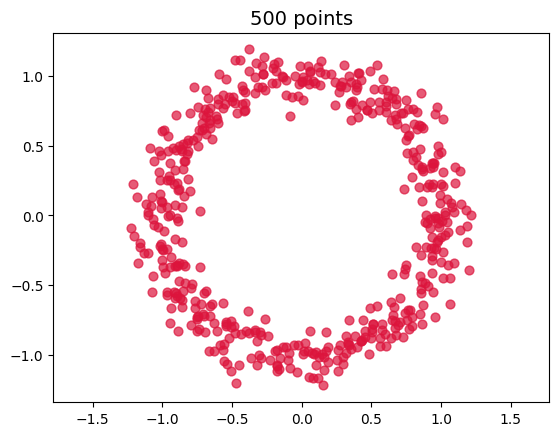

In [5]:
# Простая визуализация двумерных данных:
vis.plot_data_cloud(data)

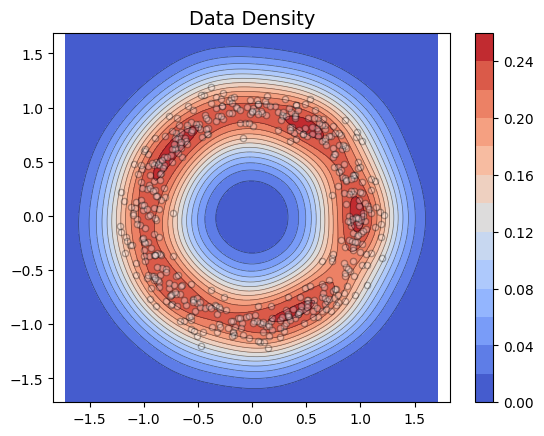

In [6]:
# Визуализация плотности данных
vis.plot_density_heatmap(data, palette='coolwarm')

## Step 1. Estimation of Betti's Dynamics

In [7]:
from betti import BettiNumbersCalculator

betti_calculator = BettiNumbersCalculator()
dynamics = betti_calculator.compute_betti_numbers_dynamics(data)

dynamics.T[-5:]

array([[0.17820515, 4.        ],
       [0.18898547, 3.        ],
       [0.19976443, 2.        ],
       [0.20513526, 1.        ],
       [1.37350047, 0.        ]])

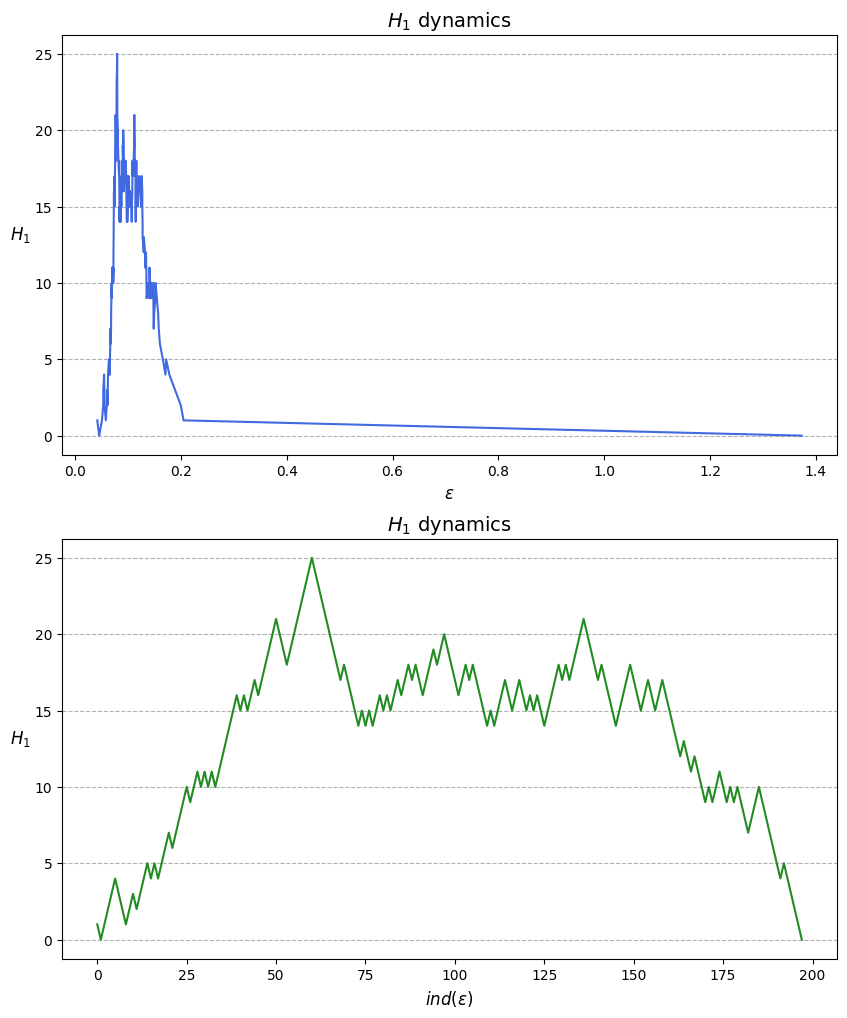

In [8]:
betti_calculator.plot_betti_numbers_dynamics()

## Step 2. Computation of Homologies

In [9]:
epsilon = 0.21

In [ ]:
from homology import MatrixHomologyCalculator

model = MatrixHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 5927/5927 [00:44<00:00, 132.15it/s]

Execution time: 0.0 min. 44.956 sec.


In [ ]:
from homology import ListHomologyCalculator

model = ListHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 5927/5927 [00:00<00:00, 25725.27it/s]

Execution time: 0.0 min. 0.326 sec.


In [10]:
from homology import ColistHomologyCalculator

model = ColistHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 500/500 [00:00<00:00, 1650.59it/s]


Execution time: 0.0 min. 0.598 sec.


In [11]:
sizes = model.get_homologies_sizes()[-5:].T
sizes

array([[18, 19, 43, 44, 45],
       [10,  3, 25, 64,  9]])

## Step 3. Visualization of topological patterns

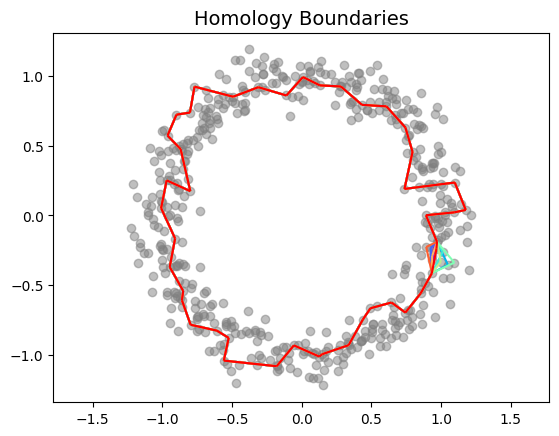

In [12]:
biggest_homologies = [
    h for h in homology_boundaries.values() if len(h.boundaries) == sizes[0, -1]
]

mutual_homology = biggest_homologies[0]
for h in biggest_homologies:
    mutual_homology += h

vis.plot_homologies(data, biggest_homologies, palette='rainbow')

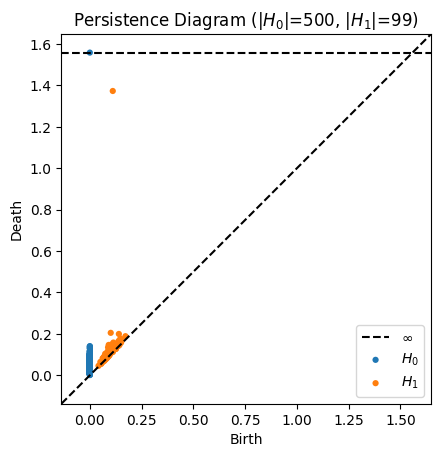

In [13]:
vis.plot_persistence_diagram(data)

/usr/local/lib/python3.13/dist-packages/gudhi/persistence_graphical_tools.py:155: UserWarning: usetex mode requires TeX.
  warnings.warn("usetex mode requires TeX.")


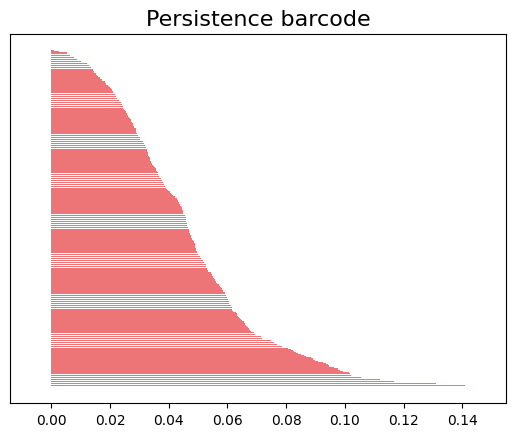

In [14]:
vis.plot_persistence_entropy(data)

## Testing the correctness of the module

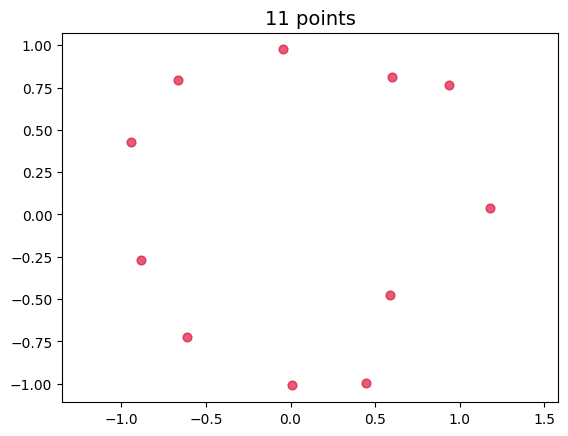

In [15]:
X, Y = make_circles(n_samples=22, noise=0.1, factor=0.99, random_state=0, shuffle=False)

data_simple = shuffle(X[Y == 0], random_state=42)

epsilon_simple = 0.79

vis.plot_data_cloud(data_simple)

In [19]:
!python -m unittest discover -s tests


Testing complex case...
Filtration computing: 100% 5927/5927 [00:00<00:00, 387034.92it/s]
Boundary matrix reduction: 100% 500/500 [00:00<00:00, 2071.15it/s]
Execution time: 0.0 min. 0.483 sec.
.
Testing simple case...
Filtration computing: 100% 12/12 [00:00<00:00, 161838.10it/s]
Boundary matrix reduction: 100% 11/11 [00:00<00:00, 20007.52it/s]
Execution time: 0.0 min. 0.002 sec.
.
----------------------------------------------------------------------
Ran 2 tests in 0.493s

OK
